# Regression and Logistic Regression

### Load the data
MLB team seasons 1962 to 2012 ("Moneyball" data), from https://www.kaggle.com/datasets/wduckett/moneyball-mlb-stats-19622012. Not included in this repo: download it and save it as `data/baseball.csv`.

In [ ]:
import pandas as pd
import sys
from pathlib import Path

# Data lives in the repo's data/ folder (see data/README.md).
# In Colab, upload the file to /content/data/ or mount Drive and point DATA_DIR at it.
IN_COLAB = 'google.colab' in sys.modules
DATA_DIR = Path('/content/data') if IN_COLAB else Path('../data')

df = pd.read_csv(DATA_DIR / 'baseball.csv', sep=',')

### Preview the data

In [ ]:
df.head()

,Team,League,Year,RS,RA,W,OBP,SLG,BA,Playoffs,RankSeason,RankPlayoffs,G,OOBP,OSLG
0,ARI,NL,2012,734,688,81,0.328,0.418,0.259,0,NaN,NaN,162,0.317,0.415
1,ATL,NL,2012,700,600,94,0.320,0.389,0.247,1,4.0,5.0,162,0.306,0.378
2,BAL,AL,2012,712,705,93,0.311,0.417,0.247,1,5.0,4.0,162,0.315,0.403
3,BOS,AL,2012,734,806,69,0.315,0.415,0.260,0,NaN,NaN,162,0.331,0.428
4,CHC,NL,2012,613,759,61,0.302,0.378,0.240,0,NaN,NaN,162,0.335,0.424


## Linear Regression

Linear regression of wins (`W`) on runs scored (`RS`): intercept, coefficient, mean squared error and R-squared.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Prepare predictors (X) and target (y)
X = df[['RS']].values
y = df[['W']].values

# Initialize and fit the model
model = LinearRegression()
model.fit(X, y)

# Calculate predictions, MSE, and r-squared
y_pred = model.predict(X)
mse = mean_squared_error(y, y_pred)
r_sq = r2_score(y, y_pred)

# Print intercept, coefficient, mean squared error, and r-squared
print("Intercept:", model.intercept_[0])
print("Coefficient:", model.coef_[0][0])
print("Mean Squared Error:", mse)
print("R-squared:", r_sq)

Intercept: 35.096418147855445
Coefficient: 0.06405951188713728
Mean Squared Error: 96.82799267415331
R-squared: 0.2618826618013622


Runs scored against wins, with the fitted regression line.

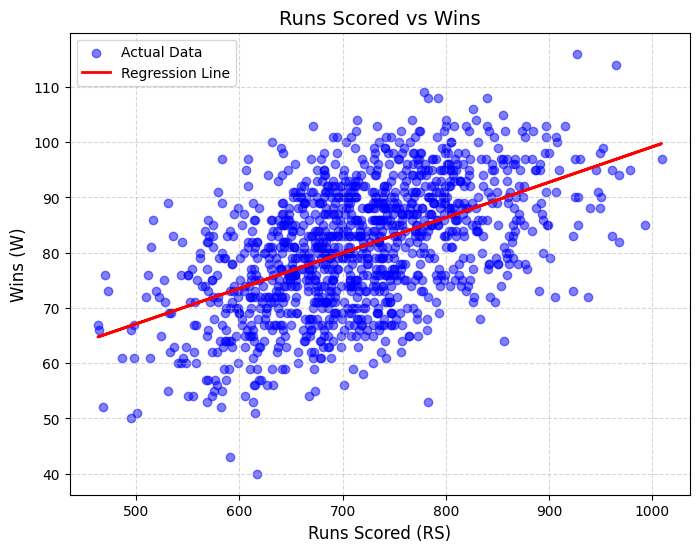

In [ ]:
import matplotlib.pyplot as plt

# Create a scatter plot of RS vs W
plt.figure(figsize=(8, 6))
plt.scatter(df['RS'], df['W'], color='blue', alpha=0.5, label='Actual Data')

# Plot the regression line
plt.plot(df['RS'], model.predict(X), color='red', linewidth=2, label='Regression Line')

# Add labels and legend
plt.xlabel('Runs Scored (RS)', fontsize=12)
plt.ylabel('Wins (W)', fontsize=12)
plt.title('Runs Scored vs Wins', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Linear multiple regression

Multiple regression of `W` on `RS`, `OBP`, `SLG` and `BA`.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Prepare predictors (X) and target (y)
X = df[['RS', 'OBP', 'SLG', 'BA']].values
y = df[['W']].values

# Initialize and fit the model
model = LinearRegression()
model.fit(X, y)

# Predictions, MSE, and R-squared
y_pred = model.predict(X)
mse = mean_squared_error(y, y_pred)
r_sq = r2_score(y, y_pred)

# Print results
print("Intercept:", model.intercept_[0])
print("Coefficients:", model.coef_[0])
print("Mean Squared Error:", mse)
print("R-squared:", r_sq)

Intercept: 54.685798223223685
Coefficients: [ 1.10727508e-01  2.94702308e+01 -1.47397736e+02 -1.54686834e+01]
Mean Squared Error: 92.83365744989813
R-squared: 0.29233137815058896


## Logistic regression

Logistic regression: predict whether a team makes the playoffs (`Playoffs`) from its wins (`W`).

In [ ]:
from sklearn.linear_model import LogisticRegression

# Fit Logistic Regression model
X = df[['W']].values
y = df['Playoffs'].values
model = LogisticRegression()
model.fit(X, y)

# Intercept and Coefficient
intercept = model.intercept_[0]
coef = model.coef_[0][0]
print(f"Intercept: {intercept}")
print(f"Coefficient: {coef}")

Intercept: -34.18312471340289
Coefficient: 0.37209406247811916


Confusion matrix (counts and percentages) and per-class accuracy, precision, recall and F1.

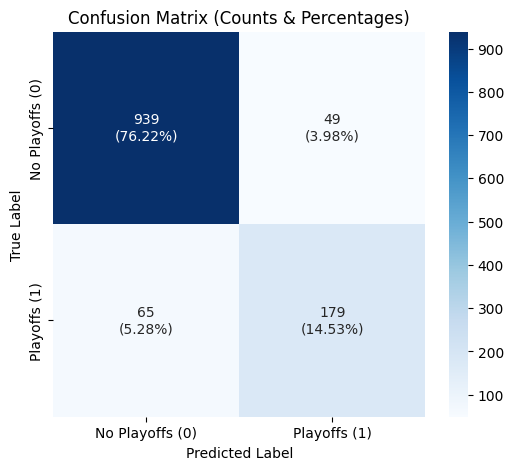

Overall Accuracy: 0.9075

Classification Report:
                 precision    recall  f1-score   support

No Playoffs (0)       0.94      0.95      0.94       988
   Playoffs (1)       0.79      0.73      0.76       244

       accuracy                           0.91      1232
      macro avg       0.86      0.84      0.85      1232
   weighted avg       0.91      0.91      0.91      1232



In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# Prepare data and predict class labels
X_eval = df[['W']].values
y_eval = df['Playoffs'].values
y_pred = model.predict(X_eval)

# Compute confusion matrix
cm = confusion_matrix(y_eval, y_pred)

# Calculate percentages for each cell relative to the total samples
cm_percent = cm.astype('float') / cm.sum() * 100

# Set up annotator text with both counts and percentages
labels = np.asarray([f"{count}\n({percent:.2f}%)" for count, percent in zip(cm.flatten(), cm_percent.flatten())]).reshape(2, 2)

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=True,
            xticklabels=['No Playoffs (0)', 'Playoffs (1)'],
            yticklabels=['No Playoffs (0)', 'Playoffs (1)'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix (Counts & Percentages)')
plt.show()

# Print overall accuracy and per-class metrics
print(f"Overall Accuracy: {accuracy_score(y_eval, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_eval, y_pred, target_names=['No Playoffs (0)', 'Playoffs (1)']))

80/20 train-test split: the same model's metrics on the training and test data.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

# Prepare features (X) and target (y) based on previous model
X = df[['W']].values
y = df['Playoffs'].values

# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Initialize and fit the logistic regression model on training data
log_reg = LogisticRegression()
log_reg.fit(X_train, y_train)

# Predictions
y_train_pred = log_reg.predict(X_train)
y_test_pred = log_reg.predict(X_test)

# Calculate metrics for training data
train_acc = accuracy_score(y_train, y_train_pred)
train_rec = recall_score(y_train, y_train_pred)
train_prec = precision_score(y_train, y_train_pred)
train_f1 = f1_score(y_train, y_train_pred)

# Calculate metrics for testing data
test_acc = accuracy_score(y_test, y_test_pred)
test_rec = recall_score(y_test, y_test_pred)
test_prec = precision_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)

# Print metrics
print("--- Training Data Metrics ---")
print(f"Accuracy:  {train_acc:.4f}")
print(f"Recall:    {train_rec:.4f}")
print(f"Precision: {train_prec:.4f}")
print(f"F1 Score:  {train_f1:.4f}")
print()
print("--- Testing Data Metrics ---")
print(f"Accuracy:  {test_acc:.4f}")
print(f"Recall:    {test_rec:.4f}")
print(f"Precision: {test_prec:.4f}")
print(f"F1 Score:  {test_f1:.4f}")

--- Training Data Metrics ---
Accuracy:  0.9076
Recall:    0.7350
Precision: 0.7946
F1 Score:  0.7636

--- Testing Data Metrics ---
Accuracy:  0.9069
Recall:    0.7273
Precision: 0.7442
F1 Score:  0.7356


5-fold cross-validation: average training and test metrics.

In [ ]:
from sklearn.model_selection import cross_validate, KFold
from sklearn.linear_model import LogisticRegression

# Prepare features (X) and target (y) based on previous model
X = df[['W']].values
y = df['Playoffs'].values

# Initialize the logistic regression model
log_reg = LogisticRegression()

# Define the 5-fold cross-validation scheme
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Define the metrics we want to calculate
scoring = ['accuracy', 'recall', 'precision', 'f1']

# Perform cross-validation and return train scores as well
cv_results = cross_validate(log_reg, X, y, cv=kf, scoring=scoring, return_train_score=True)

# Print the average metrics for both training and testing
print("--- 5-Fold Cross Validation Metrics ---")
print("Training Metrics (Average):")
print(f"Accuracy:  {cv_results['train_accuracy'].mean():.4f}")
print(f"Recall:    {cv_results['train_recall'].mean():.4f}")
print(f"Precision: {cv_results['train_precision'].mean():.4f}")
print(f"F1 Score:  {cv_results['train_f1'].mean():.4f}")
print()
print("Testing Metrics (Average):")
print(f"Accuracy:  {cv_results['test_accuracy'].mean():.4f}")
print(f"Recall:    {cv_results['test_recall'].mean():.4f}")
print(f"Precision: {cv_results['test_precision'].mean():.4f}")
print(f"F1 Score:  {cv_results['test_f1'].mean():.4f}")

--- 5-Fold Cross Validation Metrics ---
Training Metrics (Average):
Accuracy:  0.9056
Recall:    0.7037
Precision: 0.7954
F1 Score:  0.7462

Testing Metrics (Average):
Accuracy:  0.9083
Recall:    0.7149
Precision: 0.8072
F1 Score:  0.7518


Predicted playoff probabilities and class for a team with 99 wins.

In [ ]:
# Define the input for 99 wins
wins_input = [[99]]

# Get predicted probabilities
# predict_proba returns [prob_class_0, prob_class_1]
probabilities = model.predict_proba(wins_input)[0]

# Get predicted class category (0 or 1)
predicted_class = model.predict(wins_input)[0]

# Display the outputs
print(f"For a team with 99 wins:")
print(f"Probability of NOT making the playoffs: {probabilities[0]:.4f}")
print(f"Probability of making the playoffs: {probabilities[1]:.4f}")
print(f"Predicted category: {predicted_class} (0 = No Playoffs, 1 = Playoffs)")

For a team with 99 wins:
Probability of NOT making the playoffs: 0.0657
Probability of making the playoffs: 0.9343
Predicted category: 1 (0 = No Playoffs, 1 = Playoffs)
